In [8]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import category_encoders as ce


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

In [2]:
df = pd.read_csv("healthcare-dataset-stroke-data.csv")

In [3]:
df.duplicated().sum()

0

In [4]:
df.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [5]:
df.drop(columns = ['id'],inplace = True)

In [6]:
df.duplicated().sum()

0

In [7]:
df

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
...,...,...,...,...,...,...,...,...,...,...,...
5105,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

X = df.drop(columns=["stroke", "id"], errors="ignore")
y = df["stroke"].astype("int64")

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessor, numeric_features),
        ("categorical", categorical_preprocessor, categorical_features),
    ],
    sparse_threshold=0,
)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Fit preprocessing on training data only to prevent test-set leakage.
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

missing = X.isna().sum()
print(f"Raw missing values:\n{missing[missing > 0]}")
print(f"Train shape: {X_train.shape}; test shape: {X_test.shape}")
print(f"Stroke-positive rate - train: {y_train.mean():.3%}; test: {y_test.mean():.3%}")
print(f"Missing values after preprocessing - train: {np.isnan(X_train).sum()}, test: {np.isnan(X_test).sum()}")

Raw missing values:
bmi    201
dtype: int64
Train shape: (4088, 21); test shape: (1022, 21)
Stroke-positive rate - train: 4.868%; test: 4.892%
Missing values after preprocessing - train: 0, test: 0


In [10]:
X_train

array([[ 0.20566087, -0.32796178, -0.23906118, ...,  0.        ,
         1.        ,  0.        ],
       [-1.25490055, -0.32796178, -0.23906118, ...,  0.        ,
         1.        ,  0.        ],
       [ 1.04659017, -0.32796178, -0.23906118, ...,  0.        ,
         1.        ,  0.        ],
       ...,
       [ 0.78103355, -0.32796178, -0.23906118, ...,  1.        ,
         0.        ,  0.        ],
       [-0.54674956, -0.32796178, -0.23906118, ...,  0.        ,
         0.        ,  0.        ],
       [-1.65323548, -0.32796178, -0.23906118, ...,  0.        ,
         0.        ,  0.        ]])

In [11]:
X_test

array([[ 0.86955242, -0.32796178, -0.23906118, ...,  0.        ,
         1.        ,  0.        ],
       [-0.01563631, -0.32796178, -0.23906118, ...,  0.        ,
         1.        ,  0.        ],
       [-0.90082505, -0.32796178, -0.23906118, ...,  0.        ,
         0.        ,  1.        ],
       ...,
       [ 0.29417974, -0.32796178, -0.23906118, ...,  0.        ,
         1.        ,  0.        ],
       [-1.25490055, -0.32796178, -0.23906118, ...,  0.        ,
         1.        ,  0.        ],
       [ 0.33843918, -0.32796178, -0.23906118, ...,  1.        ,
         0.        ,  0.        ]])

In [12]:
y_train

845     0
3744    0
4183    0
3409    0
284     0
       ..
1434    0
461     0
1052    0
1757    0
5052    0
Name: stroke, Length: 4088, dtype: int64

In [13]:
y_test

3725    0
4481    0
1545    0
1820    0
1262    0
       ..
1042    0
1171    0
3199    0
3208    0
1819    0
Name: stroke, Length: 1022, dtype: int64

In [14]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

In [15]:
from tqdm import tqdm

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[972   0]
 [ 49   1]]


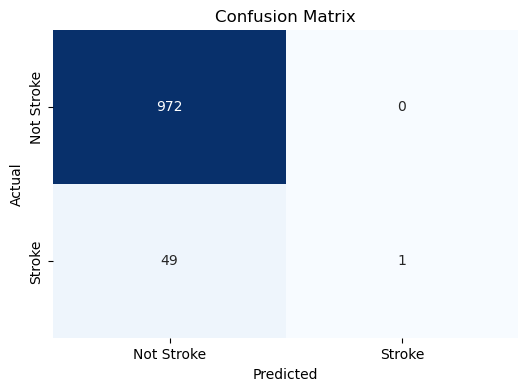


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.98       972
      Stroke       1.00      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.98      0.51      0.51      1022
weighted avg       0.95      0.95      0.93      1022

ROC-AUC: 0.8416666666666667


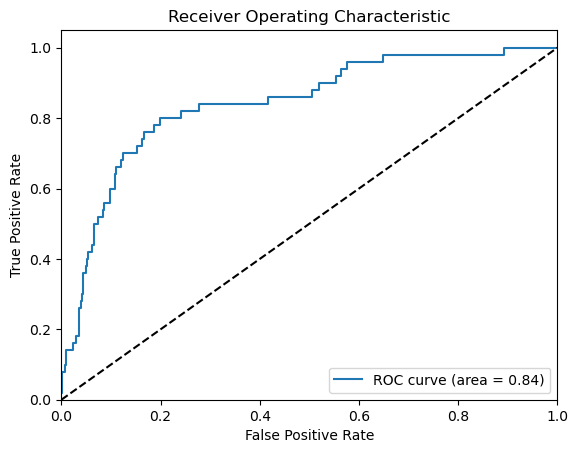

PR AUC: 0.27088268883353767


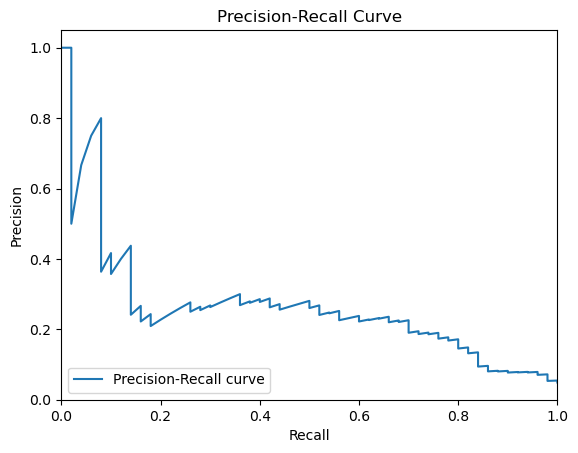

e:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
  8%|▊         | 1/13 [00:00<00:08,  1.45it/s]e:\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "e:\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "e:\anaconda\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as


Confusion Matrix:
 [[969   3]
 [ 50   0]]


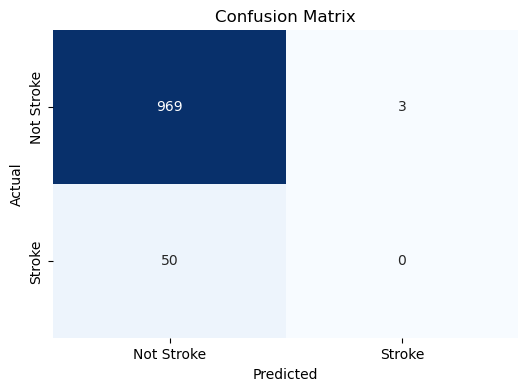


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       972
      Stroke       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022

ROC-AUC: 0.6214197530864197


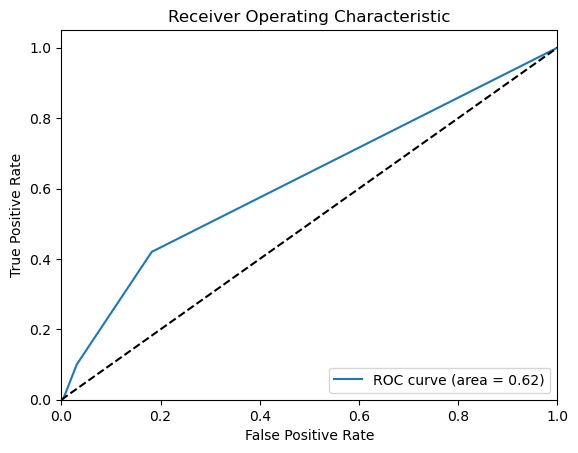

PR AUC: 0.07660084208029413


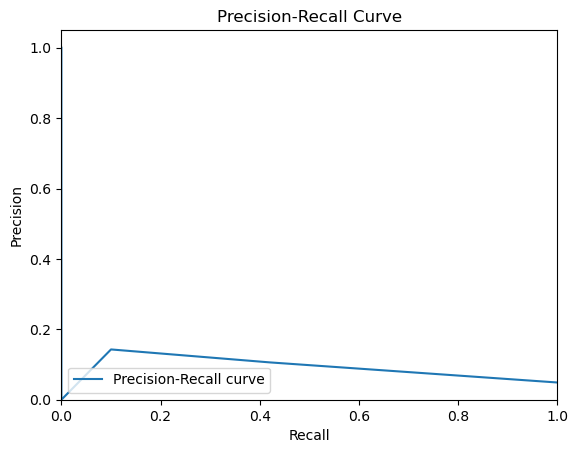

 15%|█▌        | 2/13 [00:01<00:09,  1.17it/s]e:\anaconda\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



Confusion Matrix:
 [[972   0]
 [ 50   0]]


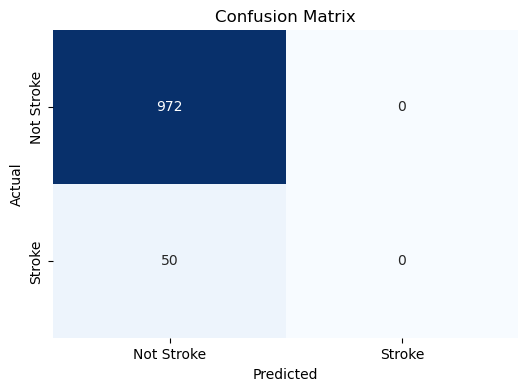


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       972
      Stroke       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022

ROC-AUC: 0.6391358024691358


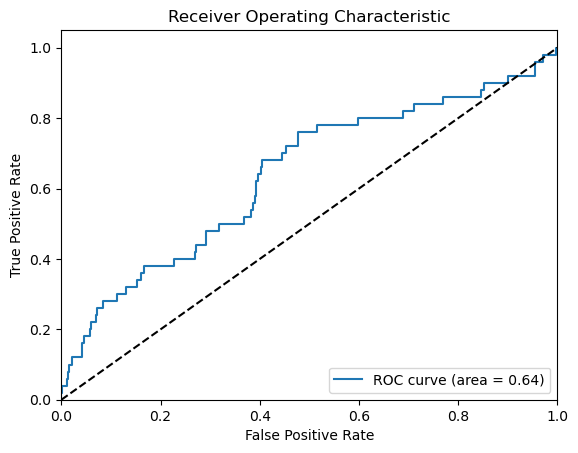

PR AUC: 0.1264322809771233


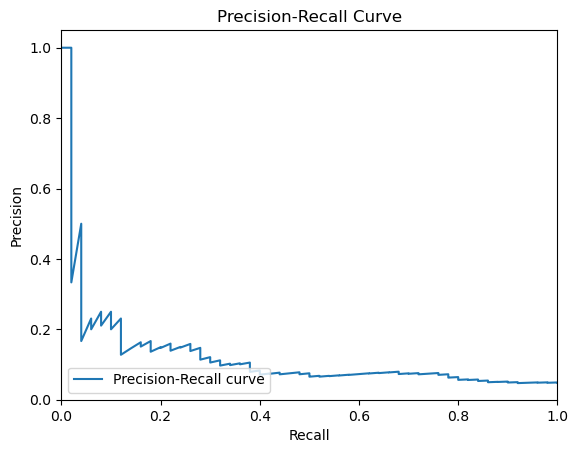

e:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
e:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
 23%|██▎       | 3/13 [00:04<00:16,  1.68s/it]


Confusion Matrix:
 [[926  46]
 [ 39  11]]


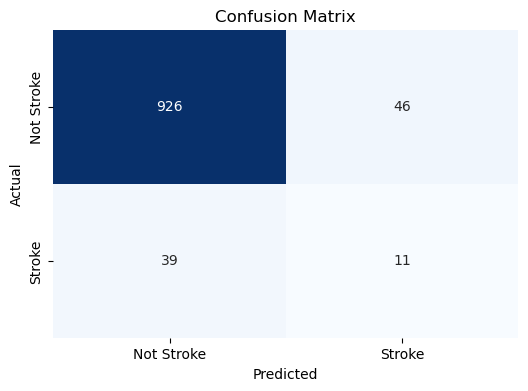


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.96      0.95      0.96       972
      Stroke       0.19      0.22      0.21        50

    accuracy                           0.92      1022
   macro avg       0.58      0.59      0.58      1022
weighted avg       0.92      0.92      0.92      1022

ROC-AUC: 0.5863374485596708


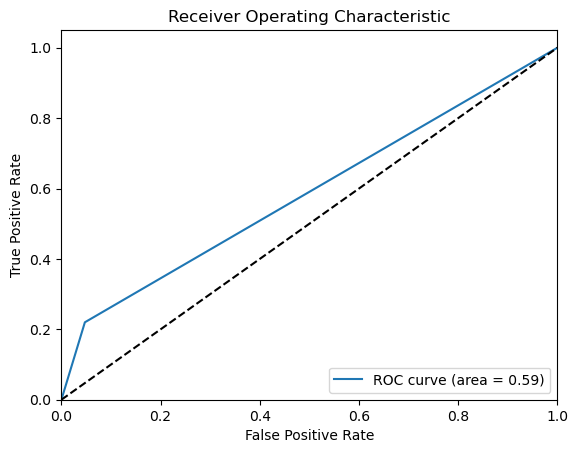

PR AUC: 0.08061661001819617


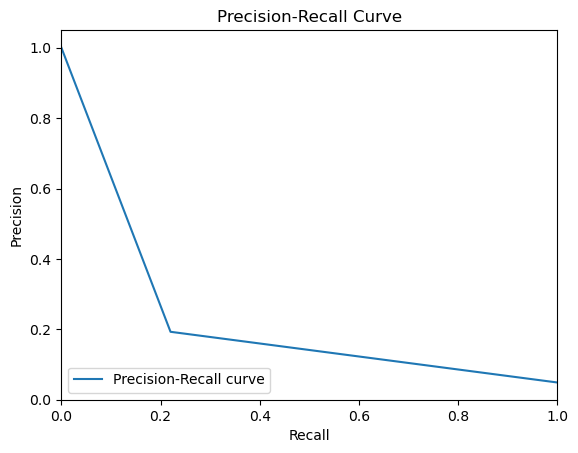

 31%|███       | 4/13 [00:05<00:11,  1.30s/it]


Confusion Matrix:
 [[256 716]
 [  1  49]]


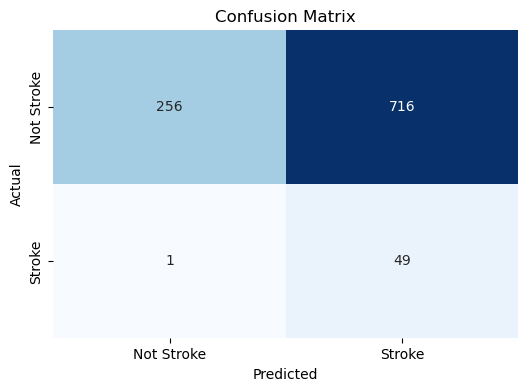


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      0.26      0.42       972
      Stroke       0.06      0.98      0.12        50

    accuracy                           0.30      1022
   macro avg       0.53      0.62      0.27      1022
weighted avg       0.95      0.30      0.40      1022

ROC-AUC: 0.7860493827160494


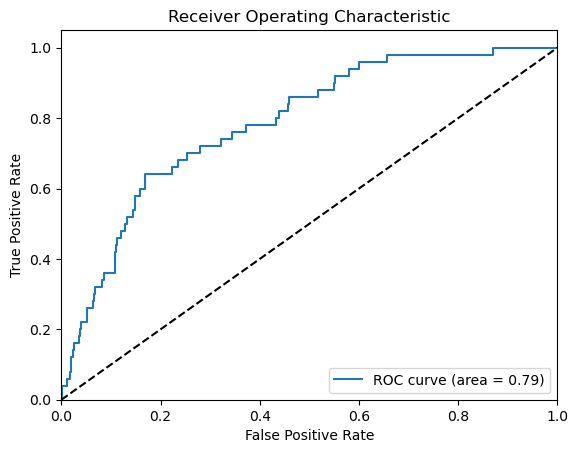

PR AUC: 0.16963810937671447


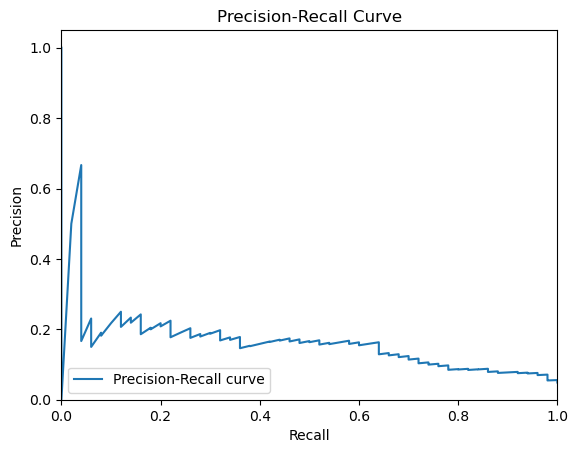

 38%|███▊      | 5/13 [00:05<00:08,  1.08s/it]


Confusion Matrix:
 [[969   3]
 [ 48   2]]


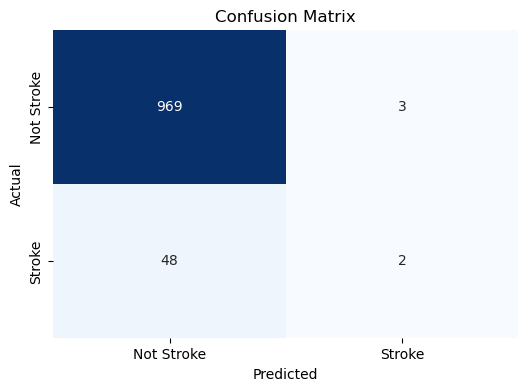


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       972
      Stroke       0.40      0.04      0.07        50

    accuracy                           0.95      1022
   macro avg       0.68      0.52      0.52      1022
weighted avg       0.93      0.95      0.93      1022

ROC-AUC: 0.7954732510288066


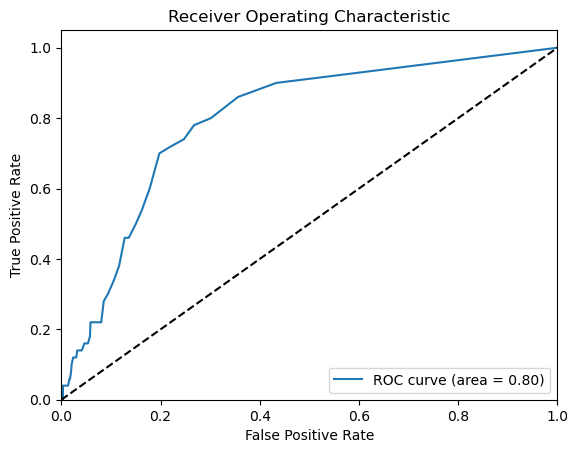

PR AUC: 0.1442799454115073


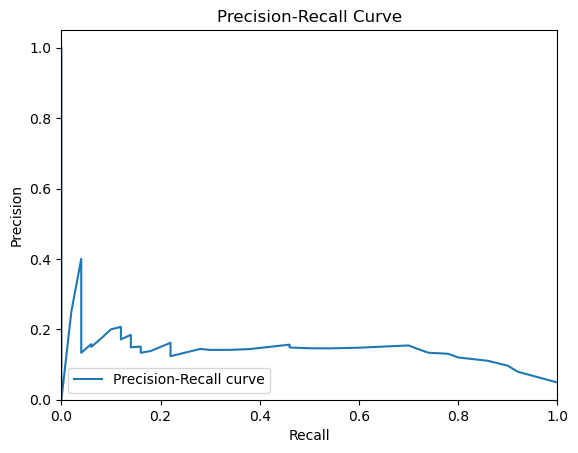

 46%|████▌     | 6/13 [00:06<00:07,  1.03s/it]


Confusion Matrix:
 [[959  13]
 [ 48   2]]


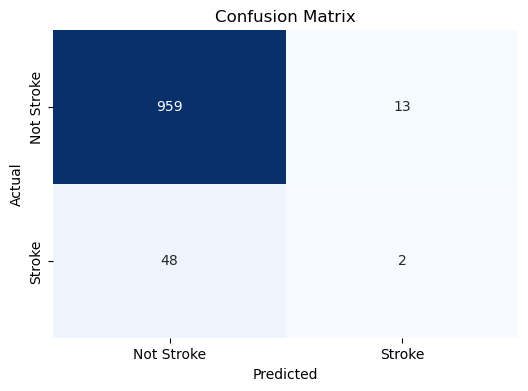


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97       972
      Stroke       0.13      0.04      0.06        50

    accuracy                           0.94      1022
   macro avg       0.54      0.51      0.52      1022
weighted avg       0.91      0.94      0.92      1022

ROC-AUC: 0.7319341563786008


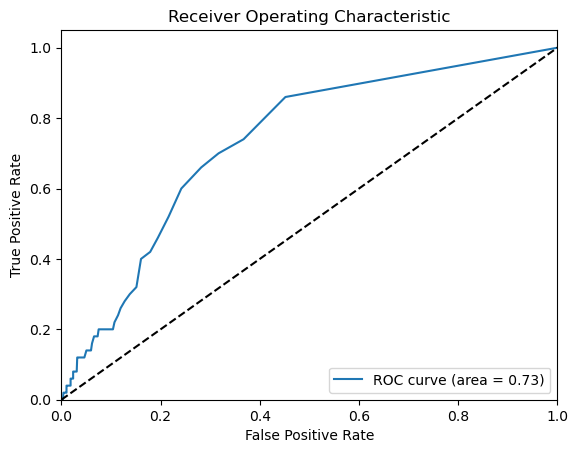

PR AUC: 0.1043469738139002


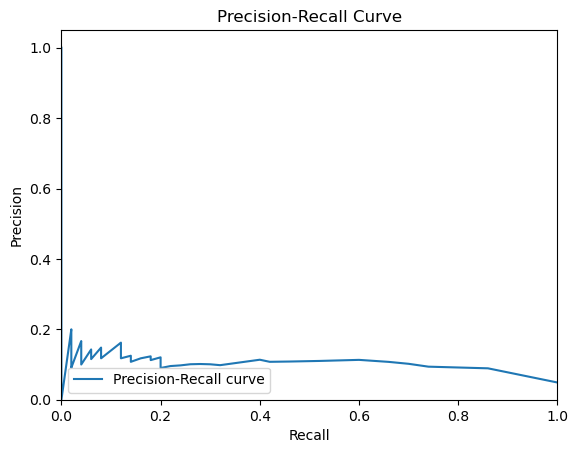

 54%|█████▍    | 7/13 [00:07<00:06,  1.02s/it]


Confusion Matrix:
 [[972   0]
 [ 50   0]]


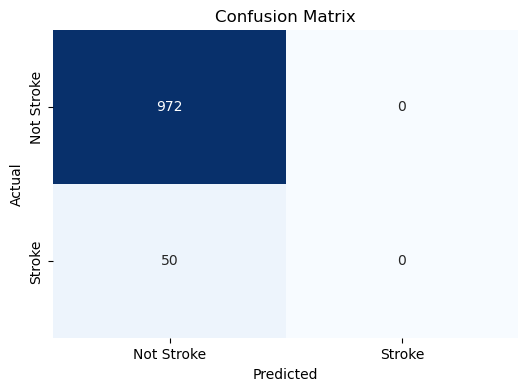


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       972
      Stroke       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022

ROC-AUC: 0.8287448559670783


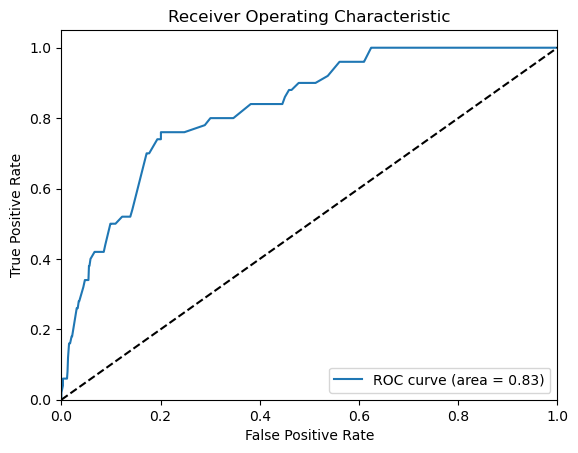

PR AUC: 0.22525228523943236


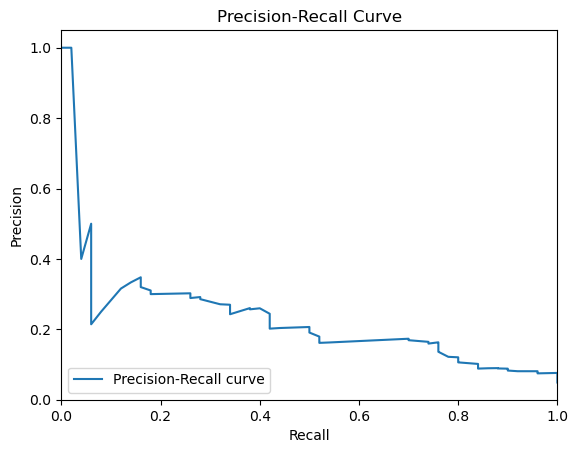

e:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
e:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
 62%|██████▏   | 8/13 [00:08<00:04,  1.03it/s]


Confusion Matrix:
 [[970   2]
 [ 48   2]]


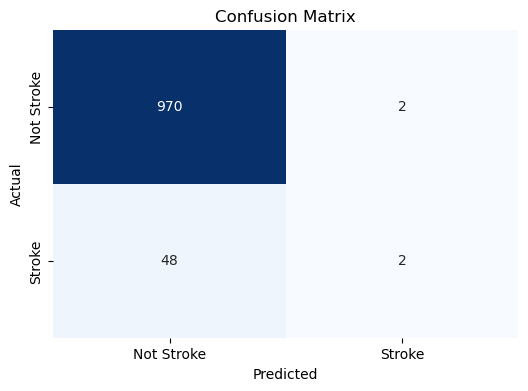


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       972
      Stroke       0.50      0.04      0.07        50

    accuracy                           0.95      1022
   macro avg       0.73      0.52      0.52      1022
weighted avg       0.93      0.95      0.93      1022

ROC-AUC: 0.8344341563786007


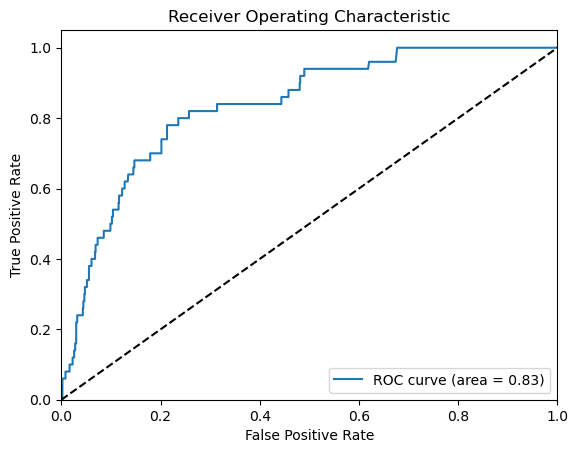

PR AUC: 0.21112522950003168


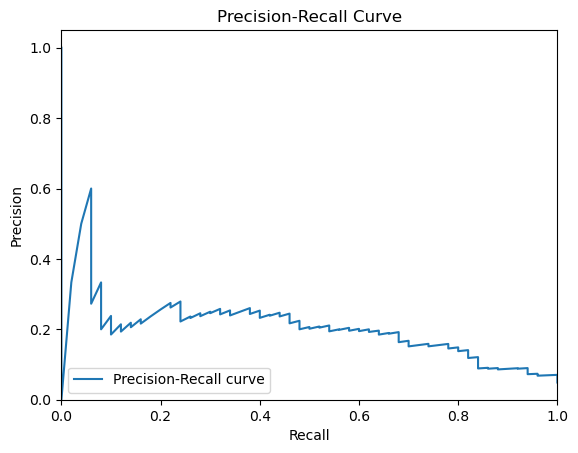

 69%|██████▉   | 9/13 [00:09<00:04,  1.01s/it]


Confusion Matrix:
 [[965   7]
 [ 48   2]]


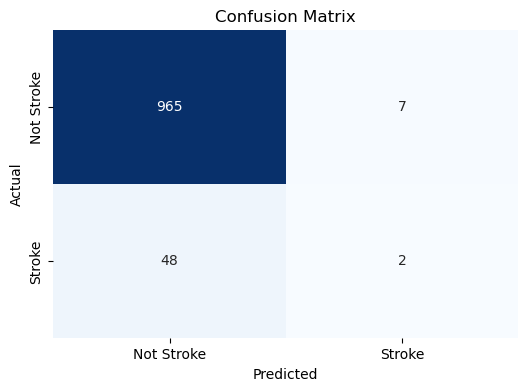


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97       972
      Stroke       0.22      0.04      0.07        50

    accuracy                           0.95      1022
   macro avg       0.59      0.52      0.52      1022
weighted avg       0.92      0.95      0.93      1022

ROC-AUC: 0.8275514403292181


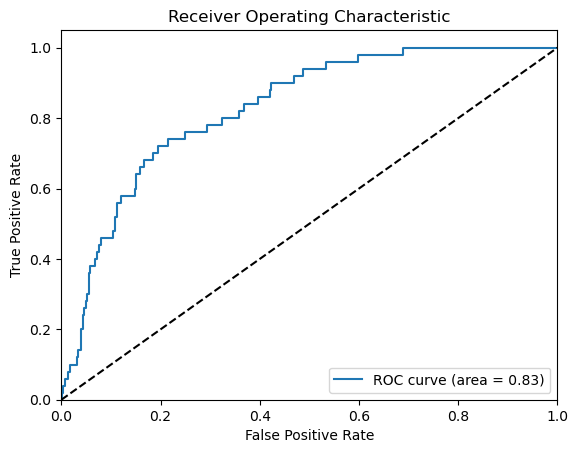

PR AUC: 0.18697142263046396


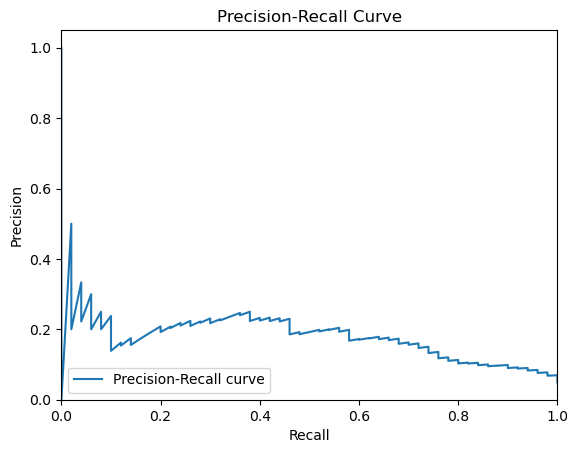

 77%|███████▋  | 10/13 [00:11<00:03,  1.18s/it]e:\anaconda\Lib\site-packages\xgboost\training.py:200: UserWarning: [08:53:16] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[964   8]
 [ 48   2]]


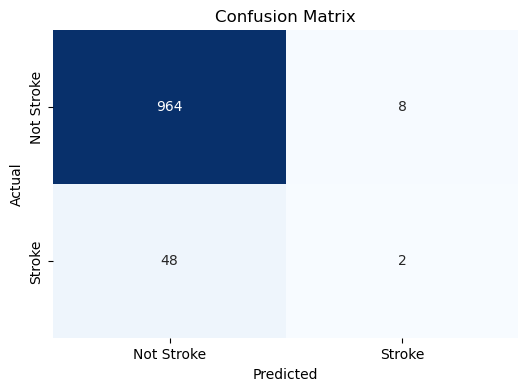


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97       972
      Stroke       0.20      0.04      0.07        50

    accuracy                           0.95      1022
   macro avg       0.58      0.52      0.52      1022
weighted avg       0.92      0.95      0.93      1022

ROC-AUC: 0.7935185185185185


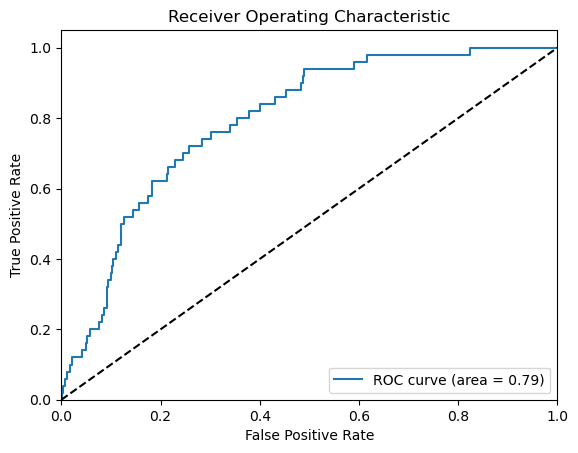

PR AUC: 0.15396855937188575


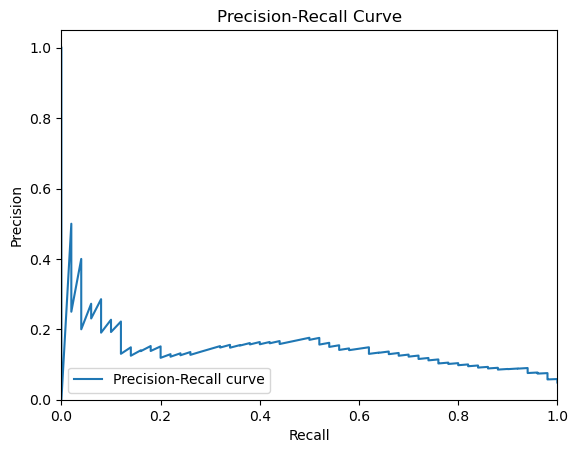

 85%|████████▍ | 11/13 [00:13<00:02,  1.39s/it]


Confusion Matrix:
 [[969   3]
 [ 49   1]]


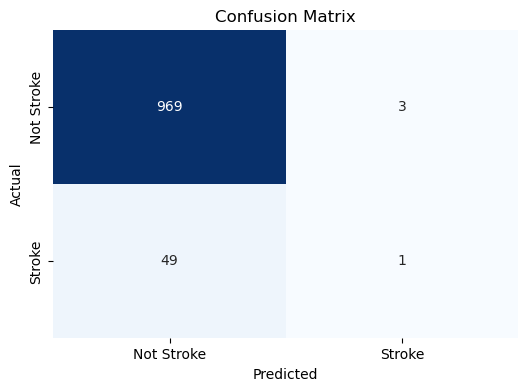


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       972
      Stroke       0.25      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.60      0.51      0.51      1022
weighted avg       0.92      0.95      0.93      1022

ROC-AUC: 0.8214197530864198


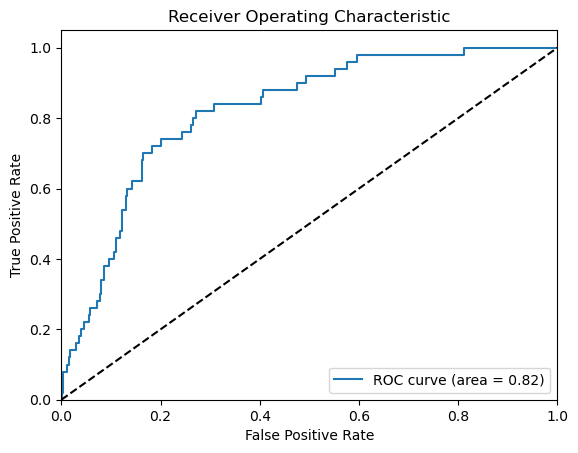

PR AUC: 0.18699457372022624


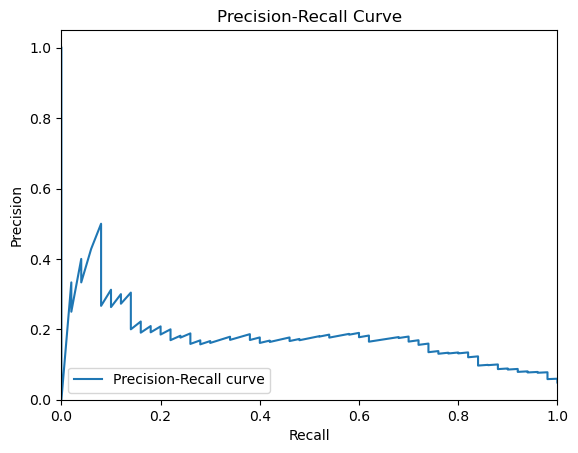

 92%|█████████▏| 12/13 [00:18<00:02,  2.63s/it]

[LightGBM] [Info] Number of positive: 199, number of negative: 3889
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002162 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 644
[LightGBM] [Info] Number of data points in the train set: 4088, number of used features: 19
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.048679 -> initscore=-2.972603
[LightGBM] [Info] Start training from score -2.972603

Confusion Matrix:
 [[966   6]
 [ 47   3]]


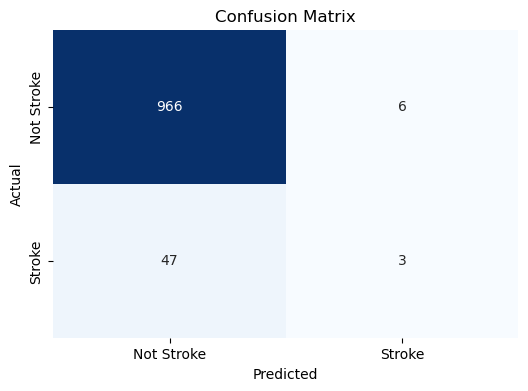


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97       972
      Stroke       0.33      0.06      0.10        50

    accuracy                           0.95      1022
   macro avg       0.64      0.53      0.54      1022
weighted avg       0.92      0.95      0.93      1022

ROC-AUC: 0.8202263374485598


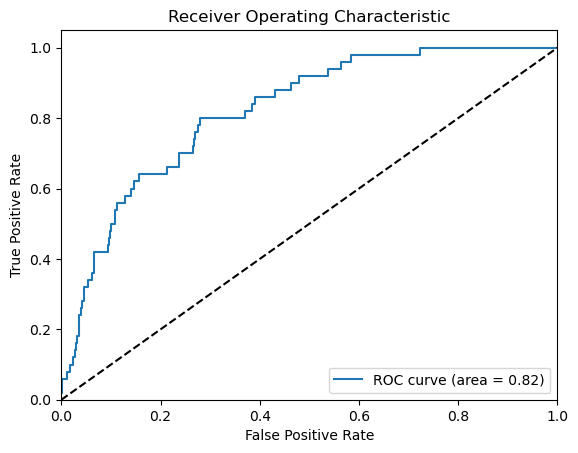

PR AUC: 0.2094276726291965


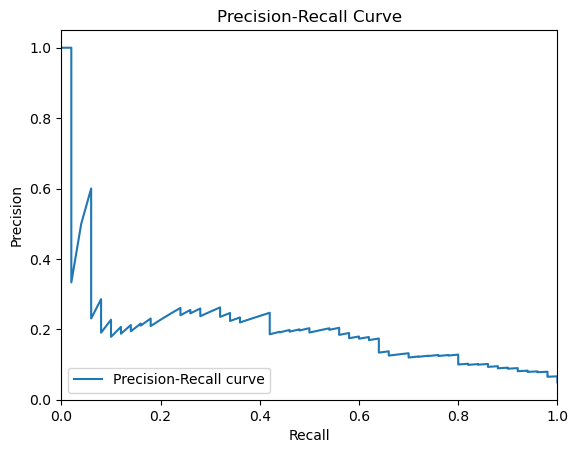

100%|██████████| 13/13 [00:19<00:00,  1.51s/it]


In [16]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)
    
    

    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Not Stroke','Stroke']
                ,yticklabels=['Not Stroke','Stroke'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

    y_pred_prob = model.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--') 
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }
    

In [17]:
res = pd.DataFrame(results)
res

,Logistic Regression,KNN,SVC,Decision Tree,Naive Bayes,Random Forest,Extra Trees,AdaBoost,Gradient Boosting,Hist Gradient Boosting,XGBoost,CatBoost,LightGBM
Train Accuracy,0.951321,0.952789,0.951321,1.000000,0.287916,1.000000,1.000000,0.951321,0.958659,0.992906,0.997309,0.977740,0.994618
Test Accuracy,0.952055,0.948141,0.951076,0.916830,0.298434,0.950098,0.940313,0.951076,0.951076,0.946184,0.945205,0.949119,0.948141
Train Precision,0.000000,0.750000,0.000000,1.000000,0.063707,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,0.990909,0.994413
Test Precision,1.000000,0.000000,0.000000,0.192982,0.064052,0.400000,0.133333,0.000000,0.500000,0.222222,0.200000,0.250000,0.333333
Train Recall,0.000000,0.045226,0.000000,1.000000,0.994975,1.000000,1.000000,0.000000,0.150754,0.854271,0.944724,0.547739,0.894472
Test Recall,0.020000,0.000000,0.000000,0.220000,0.980000,0.040000,0.040000,0.000000,0.040000,0.040000,0.040000,0.020000,0.060000
Train F1 Score,0.000000,0.085308,0.000000,1.000000,0.119746,1.000000,1.000000,0.000000,0.262009,0.921409,0.971576,0.705502,0.941799
Test F1 Score,0.039216,0.000000,0.000000,0.205607,0.120245,0.072727,0.061538,0.000000,0.074074,0.067797,0.066667,0.037037,0.101695
Train Balanced Accuracy,0.500000,0.522227,0.500000,1.000000,0.623355,1.000000,1.000000,0.500000,0.575377,0.927136,0.972362,0.773741,0.947108
Test Balanced Accuracy,0.510000,0.498457,0.500000,0.586337,0.621687,0.518457,0.513313,0.500000,0.518971,0.516399,0.515885,0.508457,0.526914
